# STREAMLINES CREATED BY 2 POINT VORTICES 

In [26]:
from matplotlib import pyplot as plt
import numpy as np
import scipy


In [72]:
from matplotlib.animation import PillowWriter

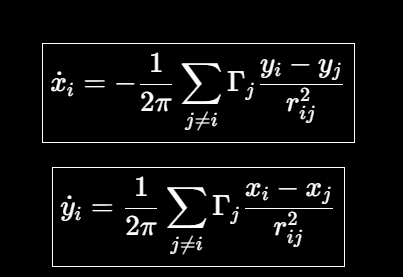

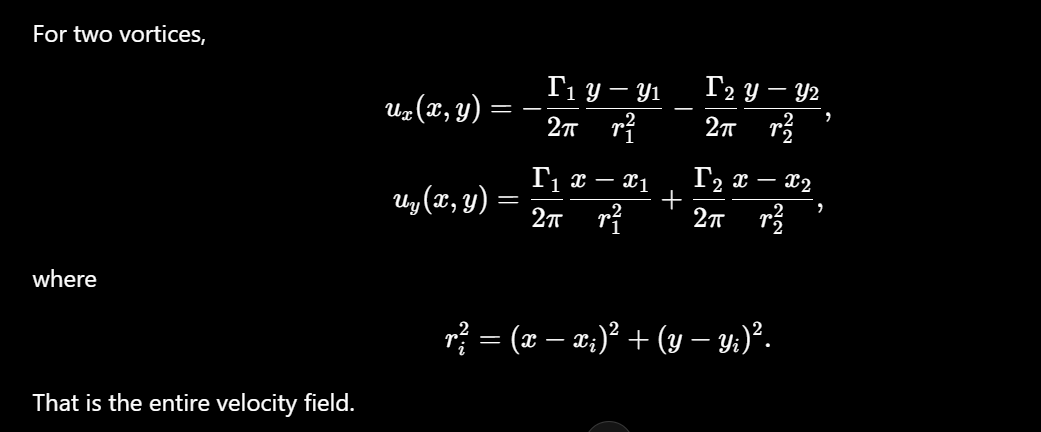

In [16]:
Gamma1 = 5.
Gamma2 = 5.

In [17]:
def calc_ux_uy_fluid_element(x,y, x1, y1, x2, y2):
    r1 = np.sqrt((x-x1)**2 + (y-y1)**2)
    r2 = np.sqrt((x-x2)**2 + (y-y2)**2)
    
    ux = (-Gamma1/(2*np.pi))*(y-y1)/r1**2. + (-Gamma2/(2*np.pi))*(y-y2)/r2**2.
    uy = (Gamma1/(2*np.pi))*(x-x1)/r1**2. + (Gamma2/(2*np.pi))*(x-x2)/r2**2.

    return ux, uy

In [18]:
def calc_ux_uy_vortex1(x1,y1, x2, y2):
    r = np.sqrt((x1-x2)**2 + (y1-y2)**2)
    
    ux = (-Gamma2/(2*np.pi))*(y1-y2)/r**2. 
    uy = (Gamma2/(2*np.pi))*(x1-x2)/r**2. 

    return ux, uy

def calc_ux_uy_vortex2(x1,y1, x2, y2):
    r = np.sqrt((x1-x2)**2 + (y1-y2)**2)
    
    ux = (-Gamma1/(2*np.pi))*(y2-y1)/r**2. 
    uy = (Gamma1/(2*np.pi))*(x2-x1)/r**2. 

    return ux, uy

Mantra: Evolve the vortices for all times first, and then trace fluid elements

## Vortices

In [75]:
tmax = 75
dt = 1e-2
t = np.linspace(0, tmax, int(tmax/dt + 1) )


x1 = np.zeros(len(t))
y1 = np.zeros(len(t))
x2 = np.zeros(len(t))
y2 = np.zeros(len(t))

x1[0] = -1.
x2[0] = 1.

#evolve vortices via RK4
for i in range(0, len(t)-1):
    #k1
    x1_k1, y1_k1 = calc_ux_uy_vortex1(x1[i], y1[i], x2[i], y2[i])
    x2_k1, y2_k1 = calc_ux_uy_vortex2(x1[i], y1[i], x2[i], y2[i])

    #k2
    x1_k2, y1_k2 = calc_ux_uy_vortex1(x1[i] + x1_k1*dt/2, y1[i] + y1_k1*dt/2, x2[i] + x2_k1*dt/2, y2[i] + y2_k1*dt/2)
    x2_k2, y2_k2 = calc_ux_uy_vortex2(x1[i] + x1_k1*dt/2, y1[i] + y1_k1*dt/2, x2[i] + x2_k1*dt/2, y2[i] + y2_k1*dt/2)

    #k3
    x1_k3, y1_k3 = calc_ux_uy_vortex1(x1[i] + x1_k2*dt/2, y1[i] + y1_k2*dt/2, x2[i] + x2_k2*dt/2, y2[i] + y2_k2*dt/2)
    x2_k3, y2_k3 = calc_ux_uy_vortex2(x1[i] + x1_k2*dt/2, y1[i] + y1_k2*dt/2, x2[i] + x2_k2*dt/2, y2[i] + y2_k2*dt/2)

    #k4
    x1_k4, y1_k4 = calc_ux_uy_vortex1(x1[i] + x1_k3*dt, y1[i] + y1_k3*dt, x2[i] + x2_k3*dt, y2[i] + y2_k3*dt)
    x2_k4, y2_k4 = calc_ux_uy_vortex2(x1[i] + x1_k3*dt, y1[i] + y1_k3*dt, x2[i] + x2_k3*dt, y2[i] + y2_k3*dt)

    x1[i+1] = x1[i] + dt*(x1_k1 + 2*x1_k2 + 2*x1_k3 + x1_k4)/6
    y1[i+1] = y1[i] + dt*(y1_k1 + 2*y1_k2 + 2*y1_k3 + y1_k4)/6
    x2[i+1] = x2[i] + dt*(x2_k1 + 2*x2_k2 + 2*x2_k3 + x2_k4)/6
    y2[i+1] = y2[i] + dt*(y2_k1 + 2*y2_k2 + 2*y2_k3 + y2_k4)/6
    

In [76]:
x1_fit = scipy.interpolate.CubicSpline(t, x1)
y1_fit = scipy.interpolate.CubicSpline(t, y1)
x2_fit = scipy.interpolate.CubicSpline(t, x2)
y2_fit = scipy.interpolate.CubicSpline(t, y2)

## Tracer Particles

In [77]:
class tracer_particle():
    def __init__(self, x0, y0, t):
        self.t = t
        self.dt = (self.t[-1] - self.t[0])/(len(t) - 1)
        self.x = np.zeros(len(t))
        self.y = np.zeros(len(t))
        self.x[0] = x0
        self.y[0] = y0

    #do RK4 to evolve particles
    def trace(self):
        for i in range(0, len(self.t)-1):
            #k1
            x_k1, y_k1 = calc_ux_uy_fluid_element(self.x[i], self.y[i], x1[i], y1[i], x2[i], y2[i])

            #k2
            x_k2, y_k2 = calc_ux_uy_fluid_element(self.x[i] + x_k1*self.dt/2, self.y[i] + y_k1*self.dt/2,
                                                  x1_fit(t[i] + self.dt/2), y1_fit(t[i] + self.dt/2),
                                                   x2_fit(t[i] + self.dt/2), y2_fit(t[i] + self.dt/2) )

            #k3
            x_k3, y_k3 = calc_ux_uy_fluid_element(self.x[i] + x_k2*self.dt/2, self.y[i] + y_k2*self.dt/2,
                                                  x1_fit(t[i] + self.dt/2), y1_fit(t[i] + self.dt/2),
                                                   x2_fit(t[i] + self.dt/2), y2_fit(t[i] + self.dt/2) )

            #k4
            x_k4, y_k4 = calc_ux_uy_fluid_element(self.x[i] + x_k3*self.dt, self.y[i] + y_k3*self.dt,
                                                  x1[i+1], y1[i+1],
                                                   x2[i+1], y2[i+1])

            self.x[i+1] = self.x[i] + self.dt*(x_k1 + 2*x_k2 + 2*x_k3 + x_k4)/6
            self.y[i+1] = self.y[i] + self.dt*(y_k1 + 2*y_k2 + 2*y_k3 + y_k4)/6

In [78]:
#trace a set of particles


x0 = 0
y0 = np.linspace(-2,2,40)


particles = []
for i in range(0, len(y0)):
    particles.append(tracer_particle(x0, y0[i], t))
    particles[i].trace()
    print('Traced particle '+str(i+1))

Traced particle 1
Traced particle 2
Traced particle 3
Traced particle 4
Traced particle 5
Traced particle 6
Traced particle 7
Traced particle 8
Traced particle 9
Traced particle 10
Traced particle 11
Traced particle 12
Traced particle 13
Traced particle 14
Traced particle 15
Traced particle 16
Traced particle 17
Traced particle 18
Traced particle 19
Traced particle 20
Traced particle 21
Traced particle 22
Traced particle 23
Traced particle 24
Traced particle 25
Traced particle 26
Traced particle 27
Traced particle 28
Traced particle 29
Traced particle 30
Traced particle 31
Traced particle 32
Traced particle 33
Traced particle 34
Traced particle 35
Traced particle 36
Traced particle 37
Traced particle 38
Traced particle 39
Traced particle 40


In [79]:
def plot_frame(index, ax):
    
    for i in range(0, len(particles)):
        ax.plot(particles[i].x[0:index+1], particles[i].y[0:index+1], c='cyan', linewidth=0.4)
    
    ax.scatter(x1[index], y1[index], c='red')
    ax.scatter(x2[index], y2[index], c='white')

    ax.annotate(f'Time: {t[index]:.2f}', (-3, 2.25), c='white')
    
    ax.set_xlim([-3.5,3.5])
    ax.set_ylim([-2.5,2.5])
    ax.set_xticks([])
    ax.set_yticks([])

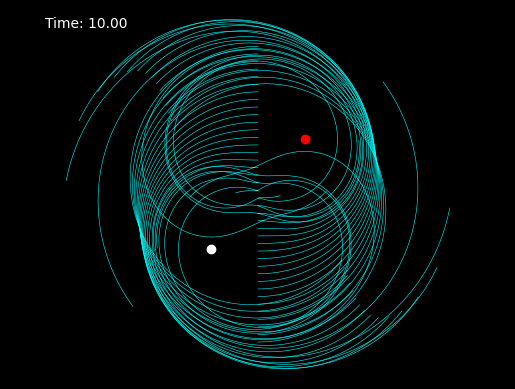

In [80]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')
plot_frame(1000,ax)
plt.show()

In [81]:
len(t)

7501

In [73]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

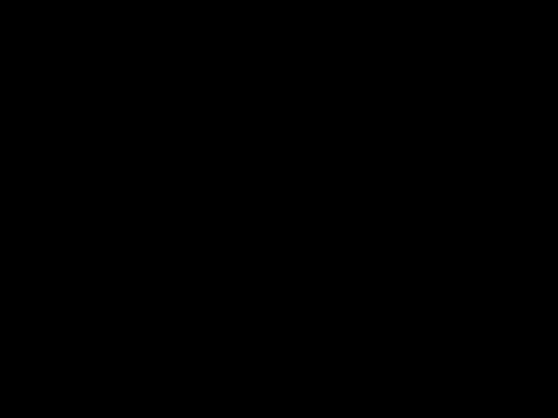

In [84]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

with writer.saving(fig, 'two_point_vortices_streamlines.gif',100):
    for i in range(0, len(t)):
        if i%20 == 0:
            plot_frame(i, ax)
            writer.grab_frame()
            plt.cla()